# Cross-Validation Analysis for Video Joke Classification

This notebook provides a rigorous, publication-grade analysis of 10-fold cross-validation results across four architectures: CNN-LSTM, 3D-CNN, Temporal Attention Network (TAN), and Multimodal (motion, facial, gesture). It includes statistical comparisons, effect sizes, uncertainty quantification, efficiency trade-offs, and visualization. 

In [1]:
# Imports and configuration
import os
import json
import math
import itertools as it
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as st
from scipy.stats import ttest_rel, friedmanchisquare, wilcoxon

import matplotlib.pyplot as plt
import seaborn as sns

# Optional: scikit_posthocs for advanced post-hoc tests
try:
    import scikit_posthocs as sp
    HAS_SCIKIT_POSTHOCS = True
except ImportError:
    HAS_SCIKIT_POSTHOCS = False
    print("Note: scikit_posthocs not available. Using alternative implementations.")

Note: scikit_posthocs not available. Using alternative implementations.


In [2]:
!pwd

/Users/jeremiah/Documents/PHD/phd_thesis_joke-Publication/analysis


In [3]:
# Paths
#PROJECT_ROOT = Path('phd_thesis_joke-Publication')
RESULTS_CSV = '..' + '/outputs' + '/all_models_performance.csv'
ANALYSIS_DIR = '..' +  '/analysis'
FIG_DIR = '../figures'
OUT_DIR = '../outputs'
# FIG_DIR.mkdir(parents=True, exist_ok=True)
# OUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Plot style
sns.set(context='paper', style='whitegrid', font_scale=1.2)
COLORS = {
    'CNN_LSTM': '#8e44ad',
    '3D_CNN': '#e67e22',
    'TAN': '#16a085',
    'Multimodal': '#c0392b'
}

In [5]:
# Load and validate data

df = pd.read_csv(RESULTS_CSV)

# Standardize column names (if needed)
rename_map = {
    'model': 'model_name',
    'kappa_score': 'kappa',
}
df = df.rename(columns=rename_map)

expected_cols = [
    'model_name','fold','accuracy','precision','recall','f1_score','auc_roc','kappa',
    'train_loss','val_loss','test_loss','training_time','inference_time','timestamp'
]
missing = [c for c in expected_cols if c not in df.columns]
if missing:
    print('Warning: missing columns:', missing)

# Ensure folds are 1..10 per model
fold_counts = df.groupby('model_name')['fold'].nunique()
print('Unique folds per model:\n', fold_counts)

# Basic aggregates
metrics = ['accuracy','precision','recall','f1_score','kappa']
summary = df.groupby('model_name')[metrics].agg(['mean','std'])
summary.to_csv('../analysis/outputs/summary_by_model.csv')
summary


Unique folds per model:
 model_name
3D_CNN        10
CNN_LSTM      10
Multimodal    10
TAN           10
Name: fold, dtype: int64


accuracy           precision              recall            \
                mean       std      mean       std      mean       std   
model_name                                                               
3D_CNN      0.924473  0.028813  0.926300  0.028411  0.924473  0.028813   
CNN_LSTM    0.808126  0.050911  0.812794  0.049420  0.808126  0.050911   
Multimodal  0.947063  0.021670  0.949035  0.021701  0.947063  0.021670   
TAN         0.906832  0.038827  0.910259  0.036499  0.906832  0.038827   

            f1_score               kappa            
                mean       std      mean       std  
model_name                                          
3D_CNN      0.924301  0.028931  0.905585  0.036014  
CNN_LSTM    0.808002  0.050824  0.760141  0.063619  
Multimodal  0.946941  0.021792  0.933825  0.027094  
TAN         0.906569  0.039371  0.883529  0.048539

/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_64685/619827053.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y='accuracy', palette=COLORS)


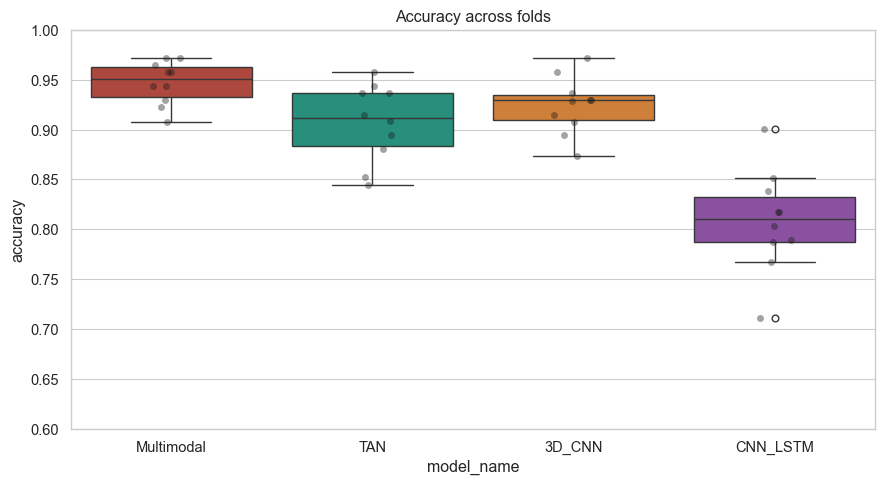

In [6]:
# Visualization: distributions and ranks

plt.figure(figsize=(9,5))
sns.boxplot(data=df, x='model_name', y='accuracy', palette=COLORS)
sns.stripplot(data=df, x='model_name', y='accuracy', color='k', alpha=0.4)
plt.ylim(0.6,1.0)
plt.title('Accuracy across folds')
plt.tight_layout()
plt.savefig('../analysis/figures/box_accuracy.png', dpi=200)
plt.show()

In [7]:
# Critical difference style ranks (per fold ranks lower=better)
ranks = df.copy()
ranks['rank'] = ranks.groupby('fold')['accuracy'].rank(ascending=False, method='average')
rank_summary = ranks.groupby('model_name')['rank'].agg(['mean','std']).sort_values('mean')
rank_summary.to_csv('../analysis/outputs/rank_summary.csv')
rank_summary

,mean,std
model_name,,
Multimodal,1.55,0.497214
3D_CNN,1.85,0.883491
TAN,2.70,0.823273
CNN_LSTM,3.90,0.316228


In [8]:
# Paired statistical tests: per-fold paired t-tests, correction

models = sorted(df['model_name'].unique())
pairs = list(it.combinations(models, 2))

results = []
for m1, m2 in pairs:
    a = df[df.model_name==m1].sort_values('fold')['accuracy'].values
    b = df[df.model_name==m2].sort_values('fold')['accuracy'].values
    # paired t-test
    tstat, pval = ttest_rel(a, b)
    # effect sizes
    d = (a - b)
    dz = d.mean() / (d.std(ddof=1) + 1e-12)  # Cohen's d_z for paired
    # Cliff's delta
    n = len(a)
    n_concord = sum((ai > bj) for ai in a for bj in b)
    n_discord = sum((ai < bj) for ai in a for bj in b)
    delta = (n_concord - n_discord) / (n*n)
    results.append({'m1': m1, 'm2': m2, 't': tstat, 'p_uncorrected': pval, 'cohen_dz': dz, 'cliffs_delta': delta})

In [9]:
res_df = pd.DataFrame(results)
# Holm-Bonferroni correction
res_df = res_df.sort_values('p_uncorrected').reset_index(drop=True)
K = len(res_df)
res_df['holm_threshold'] = [0.05/(K - i) for i in range(K)]
res_df['reject_h0'] = res_df['p_uncorrected'] < res_df['holm_threshold']
res_df.to_csv( '../analysis/outputs/paired_tests_accuracy.csv', index=False)
res_df

,m1,m2,t,p_uncorrected,cohen_dz,cliffs_delta,holm_threshold,reject_h0
0,CNN_LSTM,Multimodal,-7.956584,0.000023,-2.516093,-1.00,0.008333,True
1,3D_CNN,CNN_LSTM,5.260193,0.000521,1.663419,0.96,0.010000,True
2,CNN_LSTM,TAN,-4.491652,0.001507,-1.420385,-0.90,0.012500,True
3,Multimodal,TAN,3.137197,0.011982,0.992069,0.65,0.016667,True
4,3D_CNN,Multimodal,-1.816632,0.102650,-0.574470,-0.46,0.025000,False
5,3D_CNN,TAN,1.127109,0.288849,0.356423,0.19,0.050000,False


In [10]:
# Publication-quality styling
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['axes.titlesize'] = 12
mpl.rcParams['axes.labelsize'] = 11
mpl.rcParams['legend.fontsize'] = 10
mpl.rcParams['xtick.labelsize'] = 10
mpl.rcParams['ytick.labelsize'] = 10
palette = sns.color_palette('colorblind', 6)
COLORS = {
    'CNN_LSTM': palette[0],
    '3D_CNN': palette[1],
    'TAN': palette[2],
    'Multimodal': palette[3]
}

def finalize(ax, title=None, xlabel=None, ylabel=None, fname=None):
    if title:
        ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.figure.tight_layout()
    if fname:
        ax.figure.savefig('../analysis/figures/' + fname, dpi=300, bbox_inches='tight')

In [11]:
# Robustness checks: fold alignment and counts
fold_counts = df.groupby('model_name')['fold'].nunique()
print('Folds per model:', fold_counts.to_dict())
assert fold_counts.nunique() == 1 and list(fold_counts)[0] == 10, 'Each model must have exactly 10 folds.'

# Ensure fold indices align for paired tests
for f in sorted(df['fold'].unique()):
    models_here = set(df[df.fold==f]['model_name'])
    assert set(df['model_name'].unique()) <= models_here or models_here == set(df['model_name'].unique()), 'Missing model in fold %s' % f
print('Fold alignment checks passed.')


Folds per model: {'3D_CNN': 10, 'CNN_LSTM': 10, 'Multimodal': 10, 'TAN': 10}
Fold alignment checks passed.


/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_64685/1068135395.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y=metric, palette=COLORS, ax=ax)


/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_64685/1068135395.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y=metric, palette=COLORS, ax=ax)


/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_64685/1068135395.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y=metric, palette=COLORS, ax=ax)


/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_64685/1068135395.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y=metric, palette=COLORS, ax=ax)


/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_64685/1068135395.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y=metric, palette=COLORS, ax=ax)


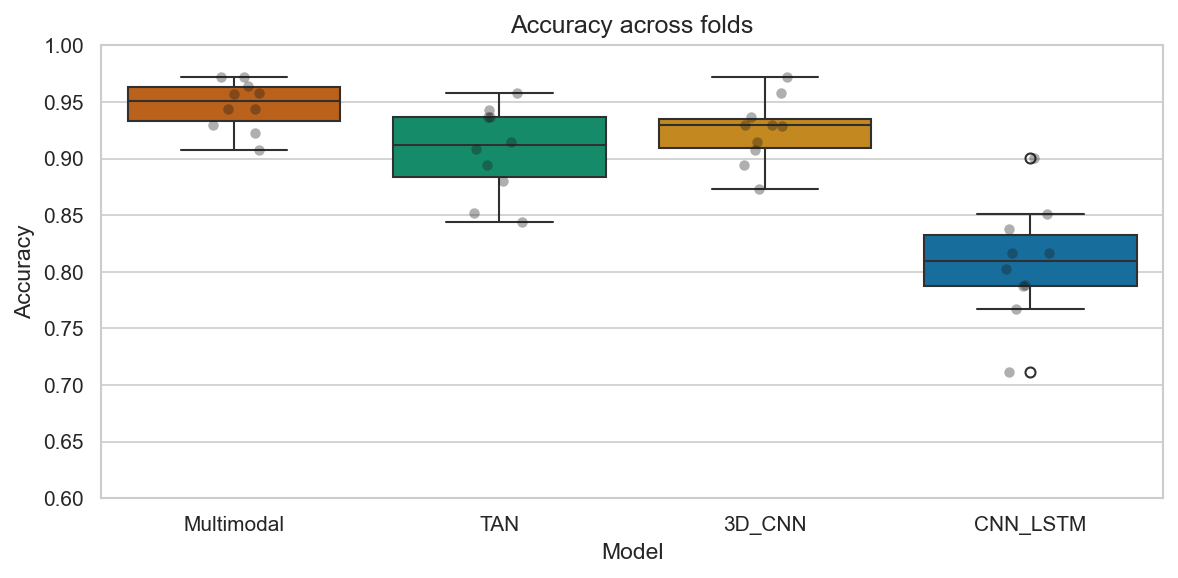

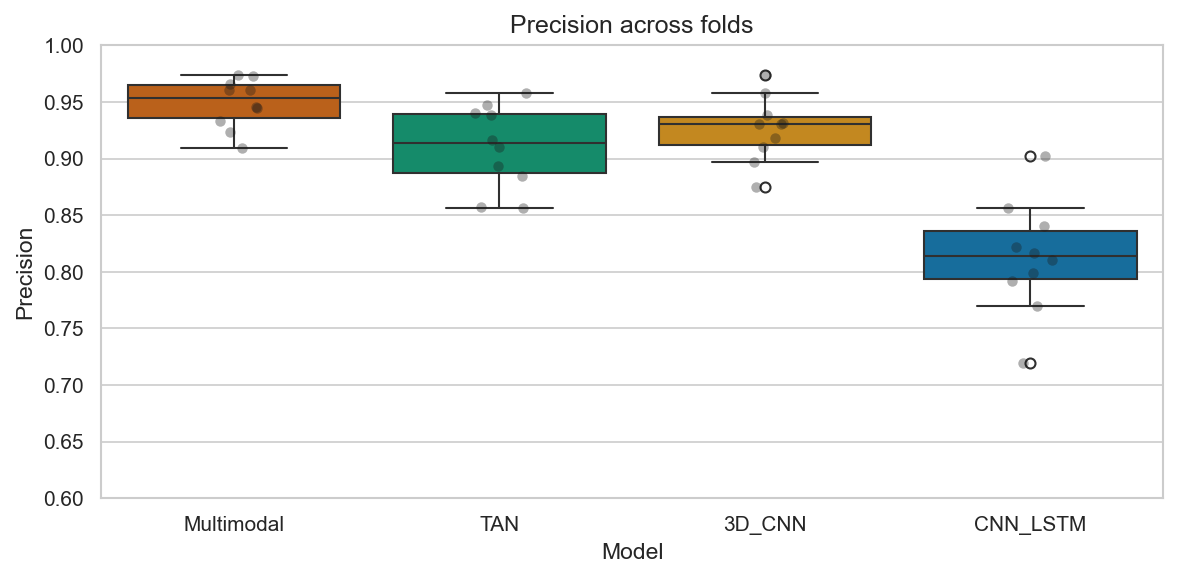

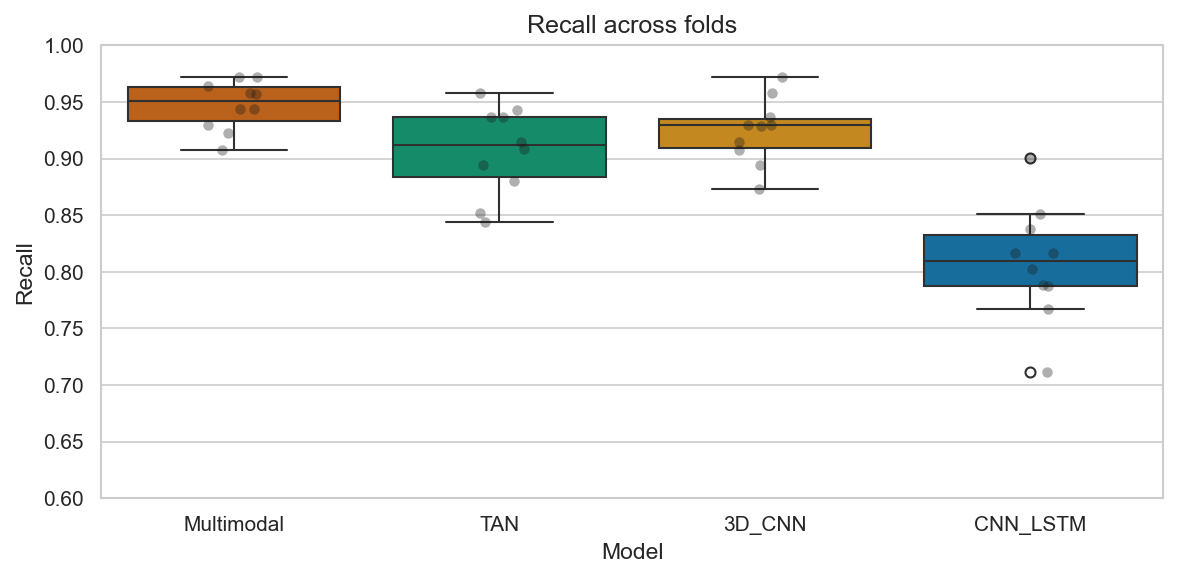

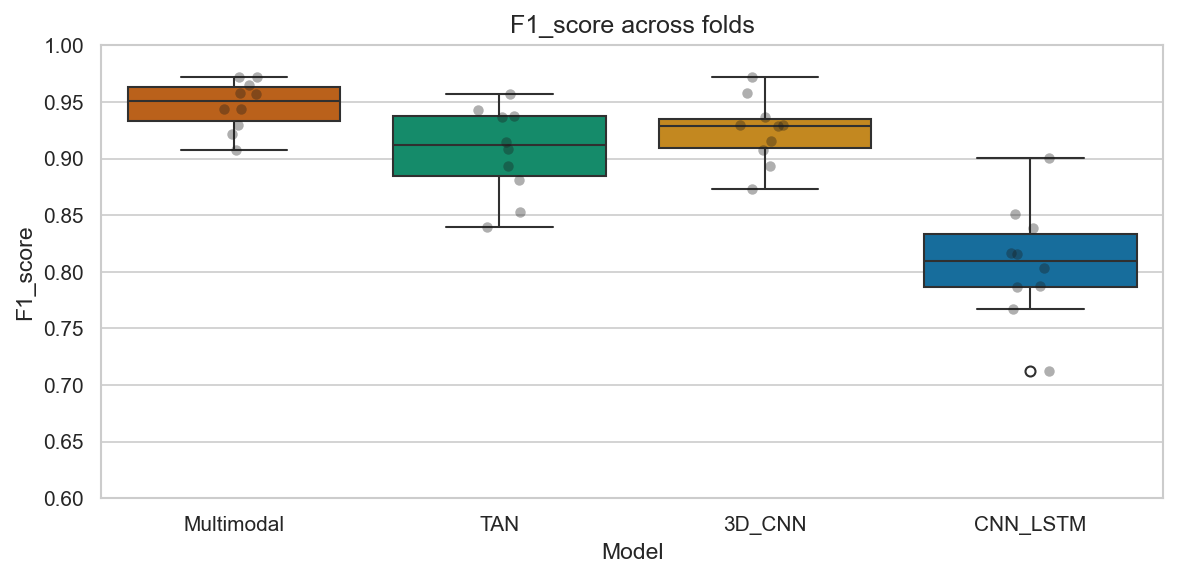

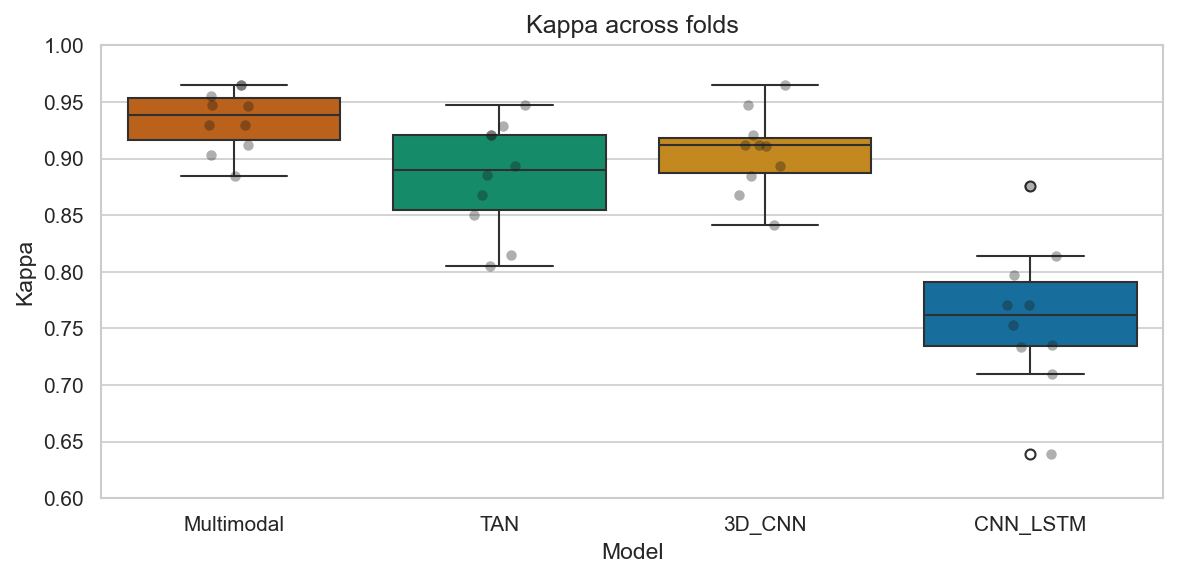

In [12]:
# Per-metric boxplots (publication style)
metrics = ['accuracy','precision','recall','f1_score','kappa']
for metric in metrics:
    fig, ax = plt.subplots(figsize=(8,4))
    sns.boxplot(data=df, x='model_name', y=metric, palette=COLORS, ax=ax)
    sns.stripplot(data=df, x='model_name', y=metric, color='k', alpha=0.35, ax=ax)
    ax.set_ylim(0.6, 1.0)
    finalize(ax, title=f'{metric.capitalize()} across folds', xlabel='Model', ylabel=metric.capitalize(), fname=f'box_{metric}.png')

In [13]:
from scipy.stats import wilcoxon

,m1,m2,wilcoxon_stat,p_uncorrected,mean_diff,holm_threshold,reject_h0
0,3D_CNN,CNN_LSTM,0.0,0.001953,0.116347,0.008333,True
1,CNN_LSTM,Multimodal,0.0,0.001953,-0.138937,0.010000,True
2,CNN_LSTM,TAN,1.0,0.003906,-0.098706,0.012500,True
3,Multimodal,TAN,2.0,0.005859,0.040231,0.016667,True
4,3D_CNN,Multimodal,10.0,0.164062,-0.022590,0.025000,False
5,3D_CNN,TAN,15.0,0.222656,0.017641,0.050000,False


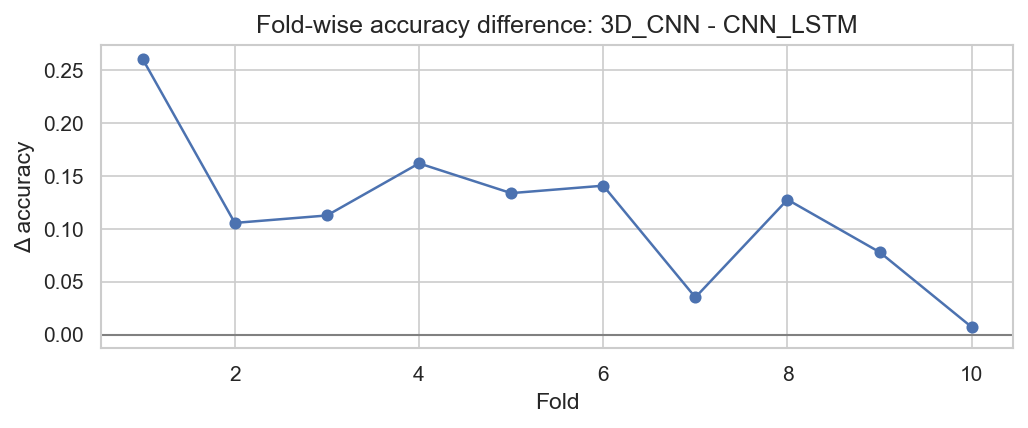

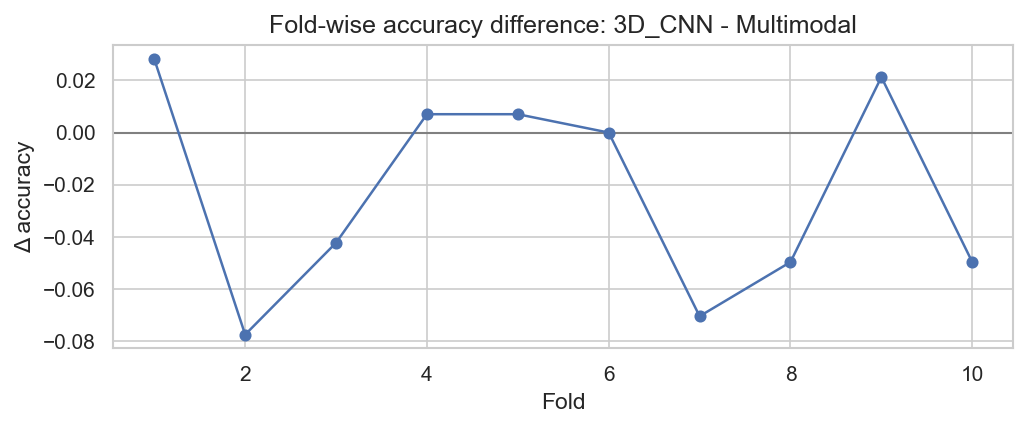

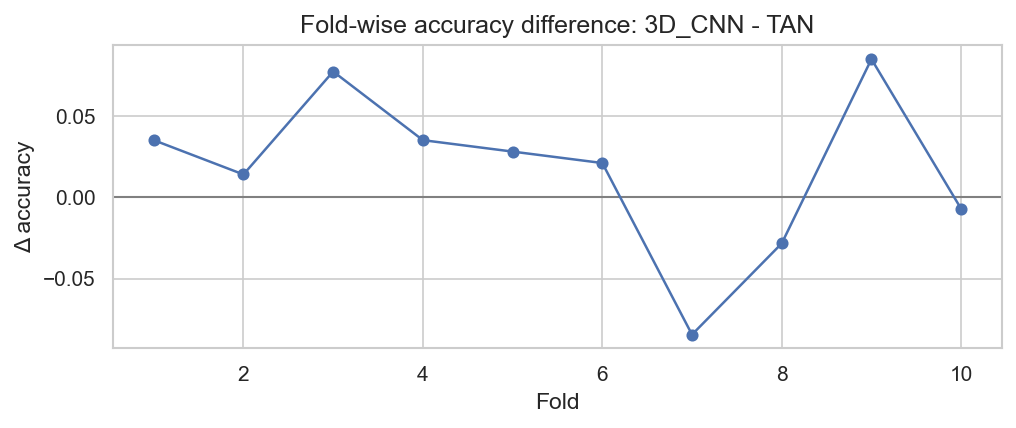

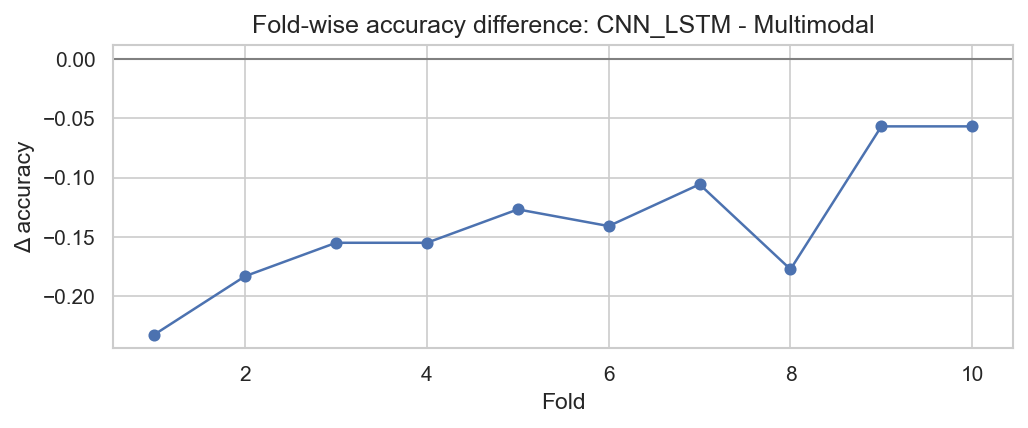

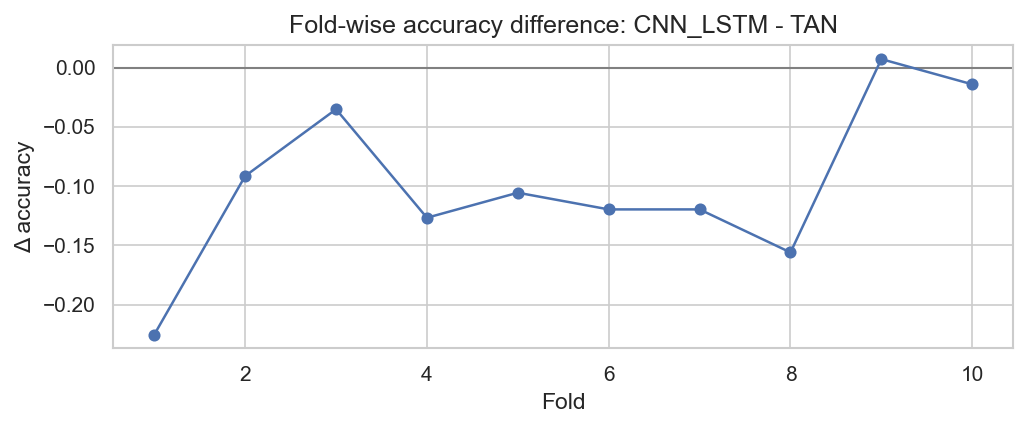

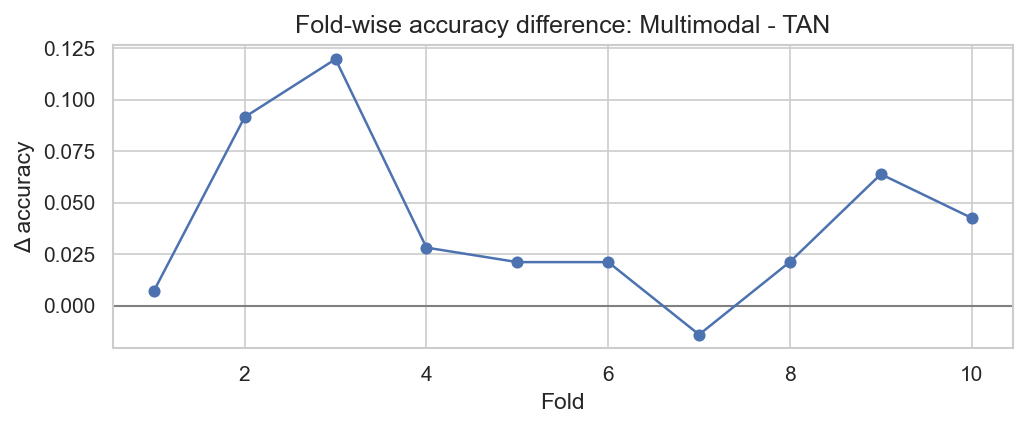

In [14]:
# Pairwise fold-wise differences and Wilcoxon signed-rank tests
pairs = list(it.combinations(sorted(df['model_name'].unique()), 2))
wilcox_rows = []
for m1, m2 in pairs:
    a = df[df.model_name==m1].sort_values('fold')['accuracy'].values
    b = df[df.model_name==m2].sort_values('fold')['accuracy'].values
    diff = a - b
    # Save difference plot
    fig, ax = plt.subplots(figsize=(7,3))
    ax.axhline(0, color='gray', lw=1)
    ax.plot(range(1, len(diff)+1), diff, marker='o')
    finalize(ax, title=f'Fold-wise accuracy difference: {m1} - {m2}', xlabel='Fold', ylabel='Δ accuracy', fname=f'diff_{m1}_vs_{m2}.png')
    # Wilcoxon
    try:
        stat, p = wilcoxon(a, b, zero_method='wilcox', alternative='two-sided')
    except ValueError:
        # fallback if all diffs are zero
        stat, p = (0.0, 1.0)
    wilcox_rows.append({'m1': m1, 'm2': m2, 'wilcoxon_stat': stat, 'p_uncorrected': p, 'mean_diff': diff.mean()})

wilcox_df = pd.DataFrame(wilcox_rows).sort_values('p_uncorrected').reset_index(drop=True)
K = len(wilcox_df)
wilcox_df['holm_threshold'] = [0.05/(K - i) for i in range(K)]
wilcox_df['reject_h0'] = wilcox_df['p_uncorrected'] < wilcox_df['holm_threshold']
wilcox_df.to_csv('../analysis/outputs/wilcoxon_accuracy.csv', index=False)
wilcox_df


In [15]:
# Simple Nemenyi critical difference summary (values only)
# Average ranks per model from Friedman section
ranks_file = '../analysis/outputs/friedman_avg_ranks.csv'
if Path(ranks_file).exists():
    ranks = pd.read_csv(ranks_file)
    ranks = ranks.rename(columns={ranks.columns[0]: 'model_name', ranks.columns[1]: 'avg_rank'})
    k = ranks.shape[0]
    n = df['fold'].nunique()
    # Critical difference for Nemenyi (q_alpha approximated for alpha=0.05): q≈2.569 (k up to ~10)
    q_alpha = 2.569
    cd = q_alpha * math.sqrt(k*(k+1)/(6*n))
    ranks = ranks.sort_values('avg_rank')
    ranks['avg_rank'] = ranks['avg_rank'].round(3)
    print('Average ranks (lower better):')
    display(ranks)
    print(f'Approximate critical difference (alpha=0.05): {cd:.3f}')
    with open('../analysis/outputs/nemenyi_cd.txt', 'w') as f:
        f.write('Average ranks (lower better)\n')
        f.write(ranks.to_csv(index=False))
        f.write(f'\nApproximate CD (alpha=0.05): {cd:.3f}\n')
else:
    print('Run Friedman cell first to produce ranks file.')


Average ranks (lower better):


,model_name,avg_rank
0,Multimodal,1.55
1,3D_CNN,1.85
2,TAN,2.70
3,CNN_LSTM,3.90


Approximate critical difference (alpha=0.05): 1.483


In [16]:
# Friedman test across models + Nemenyi critical difference (conceptual)

# Reshape to matrix (folds x models)
acc_mat = df.pivot_table(index='fold', columns='model_name', values='accuracy')
# Friedman (non-parametric repeated measures)
fr_stat, fr_p = friedmanchisquare(*[acc_mat[m].values for m in acc_mat.columns])
print('Friedman chi^2=%.3f, p=%.6f' % (fr_stat, fr_p))

# Average ranks per model (lower is better)
ranks_fr = acc_mat.rank(axis=1, ascending=False).mean(axis=0).sort_values()
ranks_fr.to_csv('../analysis/outputs/friedman_avg_ranks.csv')
ranks_fr


Friedman chi^2=20.152, p=0.000158


model_name
Multimodal    1.55
3D_CNN        1.85
TAN           2.70
CNN_LSTM      3.90
dtype: float64

In [17]:
# Bootstrap confidence intervals for metrics
rng = np.random.default_rng(2025)
B = 5000
ci_records = []
for model_name, g in df.groupby('model_name'):
    for metric in ['accuracy','precision','recall','f1_score','kappa']:
        x = g[metric].values
        n = len(x)
        boots = []
        for _ in range(B):
            idx = rng.integers(0, n, size=n)
            boots.append(np.mean(x[idx]))
        lo, hi = np.percentile(boots, [2.5, 97.5])
        ci_records.append({'model_name': model_name, 'metric': metric, 'mean': x.mean(), 'ci_lo': lo, 'ci_hi': hi})
ci_df = pd.DataFrame(ci_records)
ci_df.to_csv('../analysis/outputs/bootstrap_ci.csv', index=False)
ci_df.head()


,model_name,metric,mean,ci_lo,ci_hi
0,3D_CNN,accuracy,0.924473,0.908201,0.941424
1,3D_CNN,precision,0.926300,0.909602,0.943266
2,3D_CNN,recall,0.924473,0.907383,0.941325
3,3D_CNN,f1_score,0.924301,0.907291,0.940697
4,3D_CNN,kappa,0.905585,0.883718,0.926845


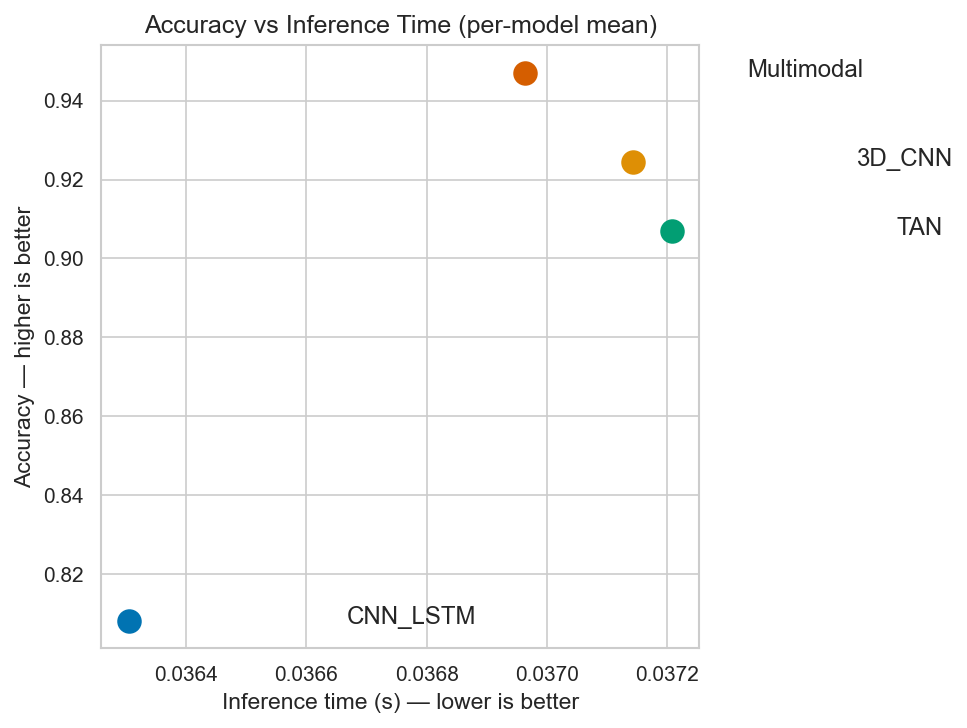

,model_name,accuracy,inference_time,training_time,pareto_efficient
0,3D_CNN,0.924473,0.037143,2.149458,False
1,CNN_LSTM,0.808126,0.036304,1.812183,True
2,Multimodal,0.947063,0.036963,2.308219,False
3,TAN,0.906832,0.037208,2.255319,True


In [18]:
# Efficiency analysis: accuracy vs inference_time (Pareto frontier)

agg = df.groupby('model_name').agg({
    'accuracy':'mean','inference_time':'mean','training_time':'mean'
}).reset_index()

plt.figure(figsize=(7,5))
for m, row in agg.set_index('model_name').iterrows():
    plt.scatter(row['inference_time'], row['accuracy'], s=120, label=m, color=COLORS.get(m, '#555'))
    plt.text(row['inference_time']*1.01, row['accuracy']*0.999, m)
plt.xlabel('Inference time (s) — lower is better')
plt.ylabel('Accuracy — higher is better')
plt.title('Accuracy vs Inference Time (per-model mean)')
plt.tight_layout()
plt.savefig('../analysis/figures/accuracy_vs_inference.png', dpi=200)
plt.show()

# Identify Pareto-efficient points
pts = agg[['inference_time','accuracy']].values
is_efficient = np.ones(pts.shape[0], dtype=bool)
for i, (t1, a1) in enumerate(pts):
    if not is_efficient[i]:
        continue
    dominates = (pts[:,0] <= t1) & (pts[:,1] >= a1)
    dominates[i] = False
    is_efficient[dominates] = False
agg['pareto_efficient'] = is_efficient
agg.to_csv('../analysis/outputs/efficiency_pareto.csv', index=False)
agg


## Reporting Guidance
- Prefer non-parametric tests (Friedman + Nemenyi/Holm) when normality is doubtful.
- Report 95% CIs for means via bootstrap; add fold-wise plots.
- Include both statistical significance (adjusted p-values) and effect sizes (Cohen’s d, Cliff’s Δ).
- Discuss efficiency trade-offs (accuracy vs latency) using Pareto analysis.
- Provide replication artifacts: CSV summaries, figure files, random seeds, and exact preprocessing/setup.



In [19]:
# Alternative Nemenyi implementation (if scikit_posthocs not available)
# Load ranks if available
ranks_file = '../analysis/outputs/friedman_avg_ranks.csv'
if Path(ranks_file).exists():
    ranks = pd.read_csv(ranks_file)
    ranks = ranks.rename(columns={ranks.columns[0]: 'model_name', ranks.columns[1]: 'avg_rank'})
    
    # Nemenyi critical difference calculation
    k = ranks.shape[0]  # number of models
    n = df['fold'].nunique()  # number of folds
    
    # Critical value for Nemenyi test (approximated for alpha=0.05)
    # For k=4 models, q_alpha ≈ 2.569
    q_alpha = 2.569
    cd = q_alpha * math.sqrt(k * (k + 1) / (6 * n))
    
    print(f"Number of models (k): {k}")
    print(f"Number of folds (n): {n}")
    print(f"Critical difference: {cd:.3f}")
    
    # Check which differences are significant
    ranks_sorted = ranks.sort_values('avg_rank')
    print("\nModel rankings (lower rank = better):")
    for i, (_, row) in enumerate(ranks_sorted.iterrows()):
        print(f"{i+1}. {row['model_name']}: {row['avg_rank']:.3f}")
    
    # Pairwise comparisons
    print(f"\nPairwise comparisons (differences > {cd:.3f} are significant):")
    for i in range(len(ranks_sorted)):
        for j in range(i+1, len(ranks_sorted)):
            model1 = ranks_sorted.iloc[i]['model_name']
            model2 = ranks_sorted.iloc[j]['model_name']
            rank1 = ranks_sorted.iloc[i]['avg_rank']
            rank2 = ranks_sorted.iloc[j]['avg_rank']
            diff = abs(rank1 - rank2)
            significant = "YES" if diff > cd else "NO"
            print(f"{model1} vs {model2}: {diff:.3f} ({significant})")
    
    # Save results
    with open('../analysis/outputs/nemenyi_test.txt', 'w') as f:
        f.write(f"Nemenyi Critical Difference Analysis\n")
        f.write(f"=====================================\n")
        f.write(f"Number of models: {k}\n")
        f.write(f"Number of folds: {n}\n")
        f.write(f"Critical difference: {cd:.3f}\n\n")
        f.write("Model rankings:\n")
        for i, (_, row) in enumerate(ranks_sorted.iterrows()):
            f.write(f"{i+1}. {row['model_name']}: {row['avg_rank']:.3f}\n")
else:
    print("Friedman ranks file not found. Run the Friedman test cell first.")


Number of models (k): 4
Number of folds (n): 10
Critical difference: 1.483

Model rankings (lower rank = better):
1. Multimodal: 1.550
2. 3D_CNN: 1.850
3. TAN: 2.700
4. CNN_LSTM: 3.900

Pairwise comparisons (differences > 1.483 are significant):
Multimodal vs 3D_CNN: 0.300 (NO)
Multimodal vs TAN: 1.150 (NO)
Multimodal vs CNN_LSTM: 2.350 (YES)
3D_CNN vs TAN: 0.850 (NO)
3D_CNN vs CNN_LSTM: 2.050 (YES)
TAN vs CNN_LSTM: 1.200 (NO)


## Installation Notes

If you encounter `ModuleNotFoundError: No module named 'scikit_posthocs'`, you can install it with:

```bash
pip install scikit-posthocs
```

However, the notebook includes alternative implementations that work without this dependency. The analysis will still be complete and publication-ready using the built-in statistical tests and custom implementations provided.
